# Explore model results

Load the data using [MIKE IO](https://dhi.github.io/mikeio/) and review it. Data is stored as a dfsu file. Specific points are stored in a dfs0 file.

In [1]:
import mikeio
import matplotlib.pyplot as plt 
plt.rcParams.update({'font.size': 10})

In [2]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = True

## Open data

There are two types of output: 2D variables and 3D variables. We start by opening both datasets to inspect the variables and the timesteps. 

In [3]:
# 2D Data
dfs2 = mikeio.open(f"{mr_fldr}2D_2023_2025_hrly.dfsu")
dfs2

<mikeio.Dfsu2DH>
number of elements: 3320
number of nodes: 1916
projection: LONG/LAT
items:
  0:  Surface elevation <Surface Elevation> (meter)
  1:  Depth averaged U velocity <u velocity component> (meter per sec)
  2:  Depth averaged V velocity <v velocity component> (meter per sec)
time: 2023-01-01 00:00:00 - 2025-12-31 23:00:00 (26304 records)

In [4]:
# 3D Data
dfs3 = mikeio.open(f"{mr_fldr}3D_2023_2025_hrly.dfsu")
dfs3

<mikeio.Dfsu3D>number of nodes: 26434
number of elements: 40500
projection: LONG/LAT
number of sigma layers: 10
max number of z layers: 30
items:
  0:  U velocity <u velocity component> (meter per sec)
  1:  V velocity <v velocity component> (meter per sec)
  2:  W velocity <w velocity component> (meter per sec)
  3:  Density <Density> (kg per meter pow 3)
  4:  Temperature <Temperature> (degree Celsius)
  5:  Salinity <Salinity> (PSU)
time: 2023-01-01 00:00:00 - 2025-12-31 23:00:00 (26304 records)

## Mesh and bathymetry

We can also inspect the geometry using the built-in plotting methods.

In [5]:
geom = dfs2.geometry

Calculate the total area covered (in km^2)

In [6]:
geom.get_element_area().sum()/(10**6)

np.float64(2045.378027184835)

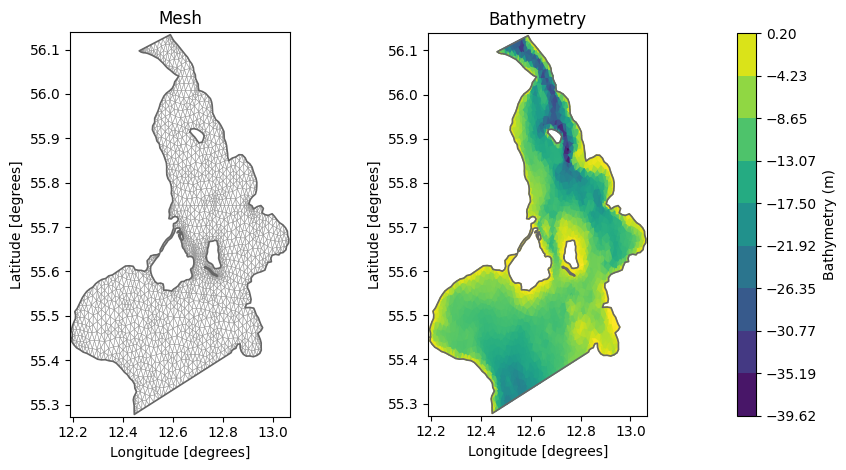

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.8))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
if save_png:
    plt.savefig(f"{fig_fldr}geometry.png")
plt.show()

## 2D outputs
We now explore the data stored in the 2D file.

In [8]:
ds2 = dfs2.read()

### Area overview plot
Show state variables on a specific date

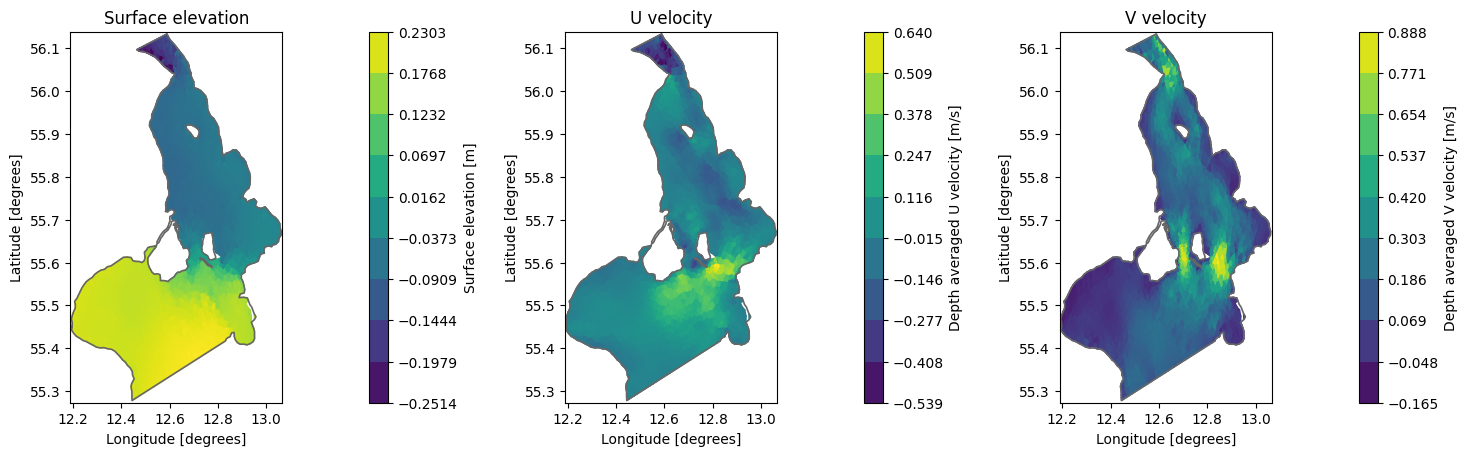

In [9]:
# Select time step and plot items
plot_time = "2024-05-01" if "2024-05-01" in ds2.time else ds2.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
ds2["Surface elevation"].sel(time=plot_time).plot(ax=axs[0], title="Surface elevation")
ds2["Depth averaged U velocity"].sel(time=plot_time).plot(ax=axs[1], title="U velocity")
ds2["Depth averaged V velocity"].sel(time=plot_time).plot(ax=axs[2], title="V velocity")
plt.tight_layout()
plt.show()

### Timeseries plot
Show state variables in a specific coordinate over time

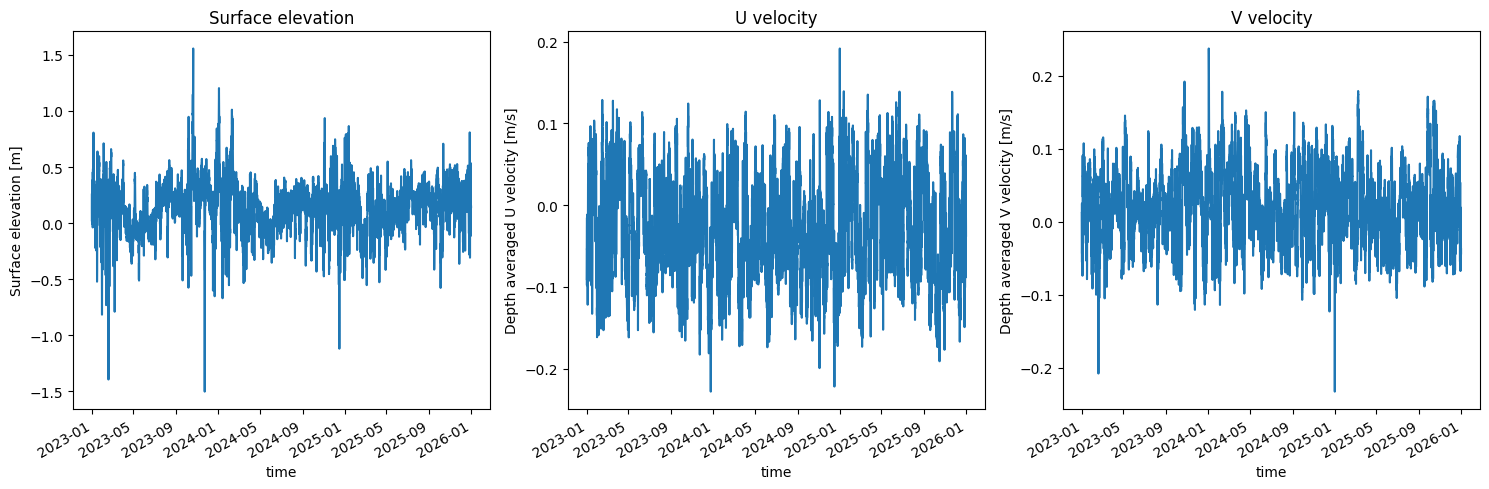

In [10]:
# Select spatial point and plot items
p = (12.5, 55.5)
fig,axs = plt.subplots(1,3, figsize=(15,5))
ds2["Surface elevation"].sel(x=p[0],y=p[1]).plot(ax=axs[0],title="Surface elevation")
ds2["Depth averaged U velocity"].sel(x=p[0],y=p[1]).plot(ax=axs[1],title="U velocity")
ds2["Depth averaged V velocity"].sel(x=p[0],y=p[1]).plot(ax=axs[2],title="V velocity")
plt.tight_layout()
plt.show()

## 3D outputs
And now, we inspect the 3D data.

In [11]:
times = slice("2024-05-01", "2024-07-31") if "2024-05-01" in dfs3.time else slice(dfs3.time[0], dfs3.time[-1])
ds3 = dfs3.read(time=times)

### Area overview plots
Visualize different 3D outputs in different layers. Here, just the top and bottom layers are shown.

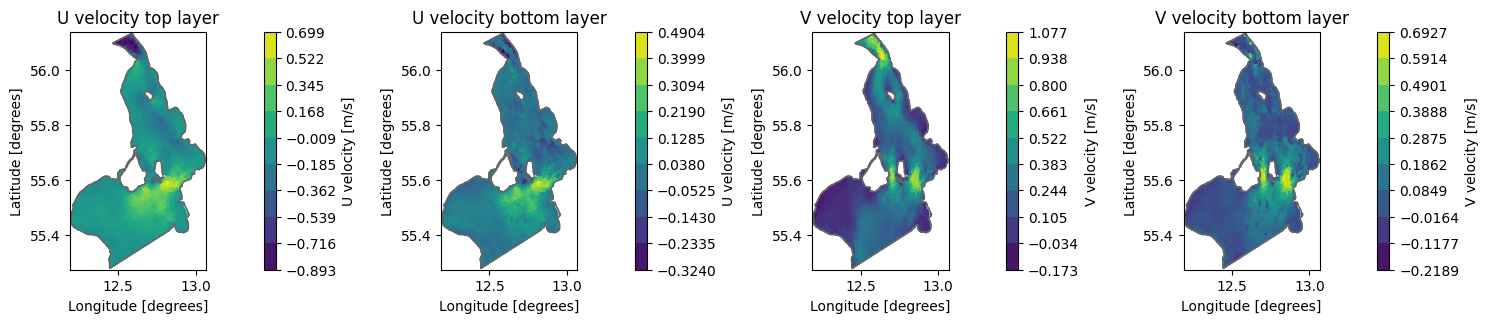

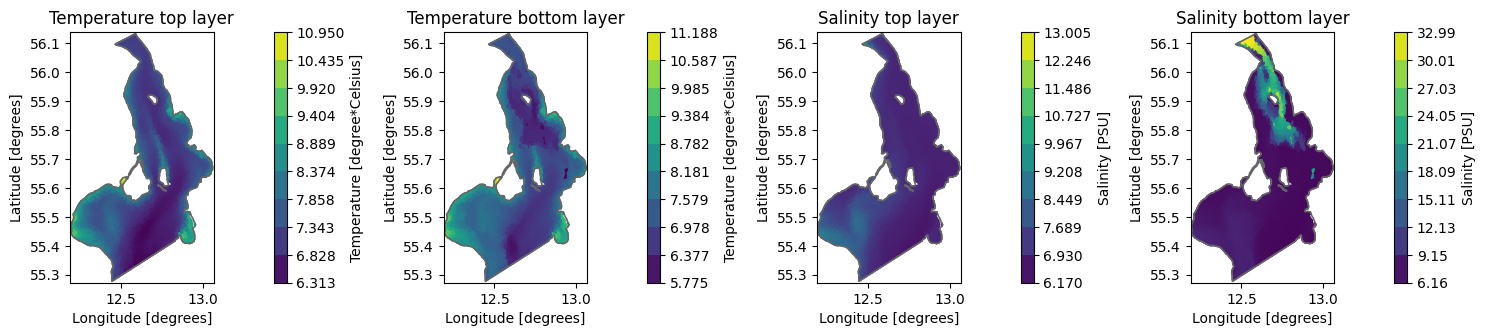

In [12]:
plot_time = "2024-05-01" if "2024-05-01" in ds2.time else ds2.time[-1]
fig,axs = plt.subplots(1, 4, figsize=(15,5))
ds3[0].sel(layers='top',time=plot_time).plot(ax=axs[0], title="U velocity top layer");
ds3[0].sel(layers='bottom',time=plot_time).plot(ax=axs[1], title="U velocity bottom layer");
ds3[1].sel(layers='top',time=plot_time).plot(ax=axs[2], title="V velocity top layer");
ds3[1].sel(layers='bottom',time=plot_time).plot(ax=axs[3], title="V velocity bottom layer");
plt.tight_layout()
plt.show()

plot_time = "2024-05-01" if "2024-05-01" in ds2.time else ds2.time[-1]
fig,axs = plt.subplots(1, 4, figsize=(15,5))
ds3[4].sel(layers='top',time=plot_time).plot(ax=axs[0], title="Temperature top layer");
ds3[4].sel(layers='bottom',time=plot_time).plot(ax=axs[1], title="Temperature bottom layer");
ds3[5].sel(layers='top',time=plot_time).plot(ax=axs[2], title="Salinity top layer");
ds3[5].sel(layers='bottom',time=plot_time).plot(ax=axs[3], title="Salinity bottom layer");
plt.tight_layout()
plt.show()

#### Plotting middle layers
The plot below shows the temperature variable in every other layer (there are up to 40 layers in total, but only layer 4 and up are occupied). The plot shows that the deepest layers are only present for some of the elements, whereas the higher the layer, the more of the domain is covered, as the domain is mainly shallow waters.

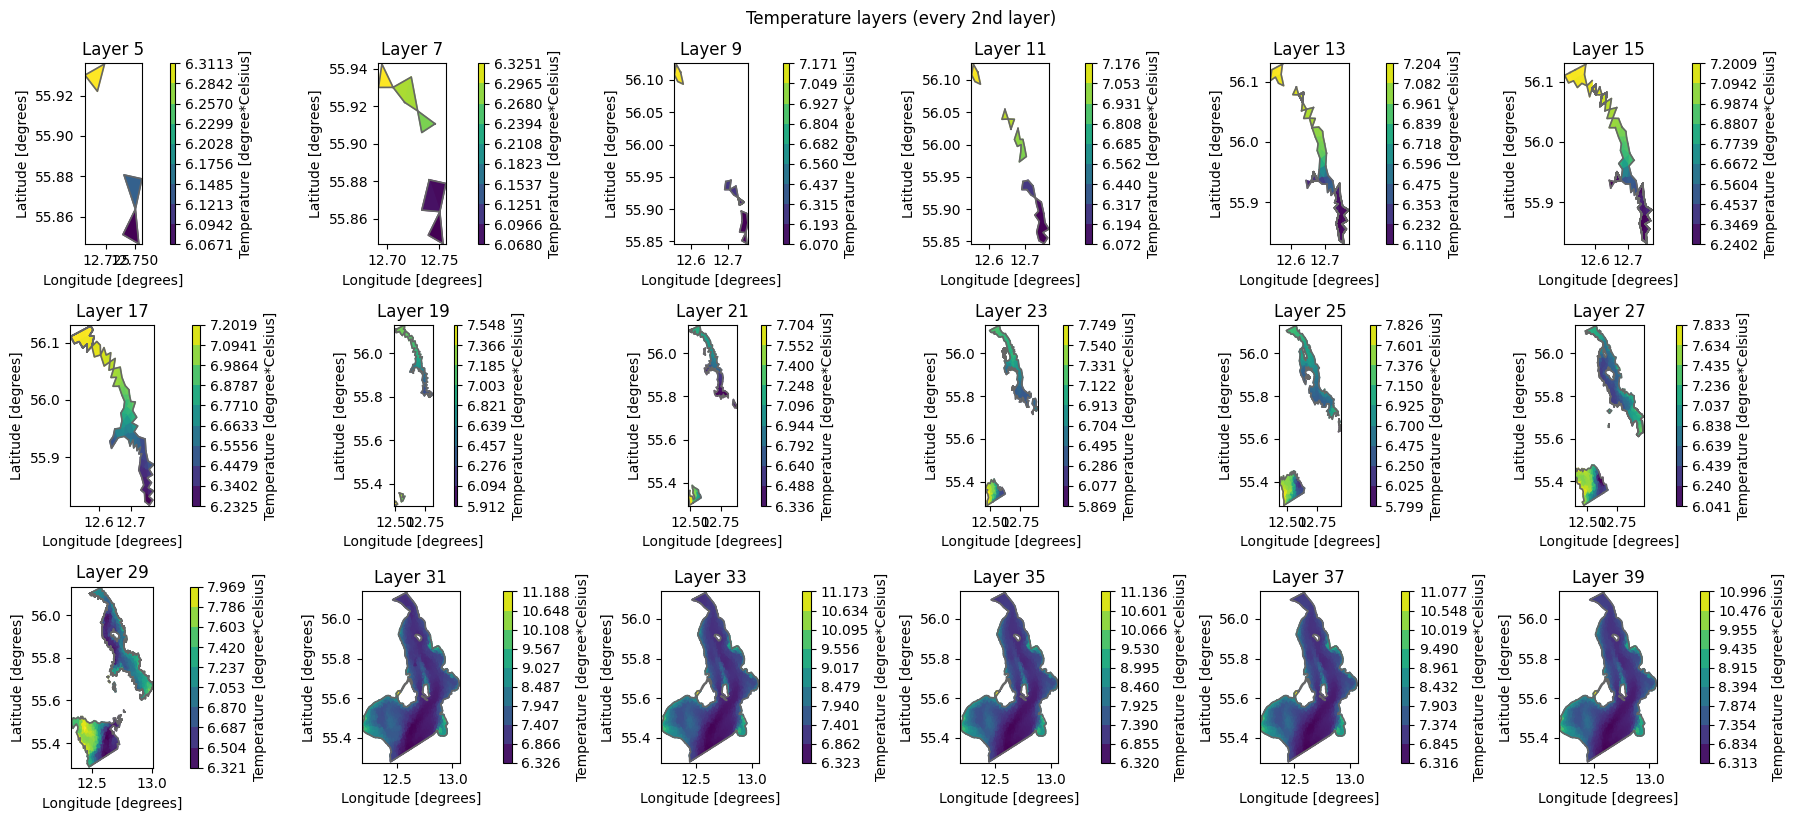

In [13]:
fig,axs = plt.subplots(3, 6, figsize=(18,8))
axs = axs.flatten()
ax_idx = 0
for i in range(2,20):
    ds3[4].sel(time=plot_time,layers=i*2).plot(ax=axs[ax_idx], title="Layer "+str(i*2+1))
    ax_idx += 1
plt.tight_layout()
plt.suptitle("Temperature layers (every 2nd layer)", y=1.02)
plt.show()


### Timeseries plot
Show state variables in a specific coordinate and layer over time

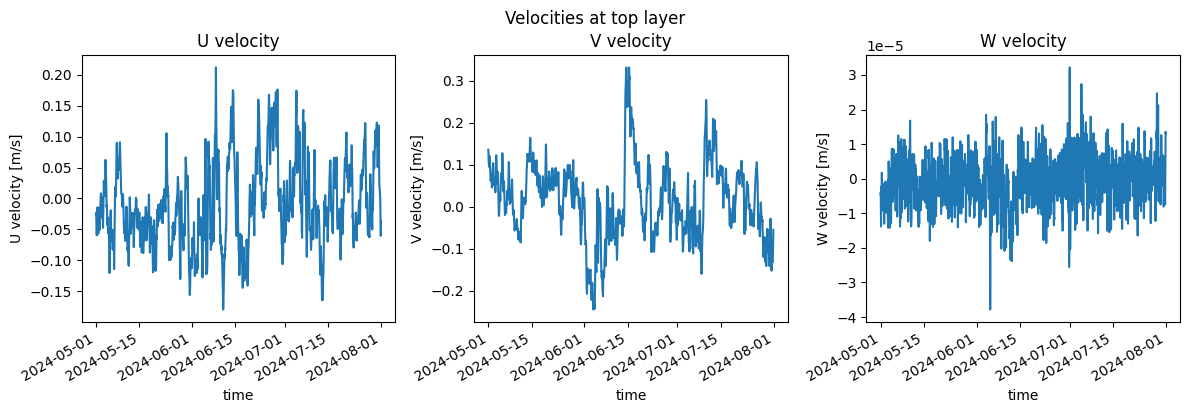

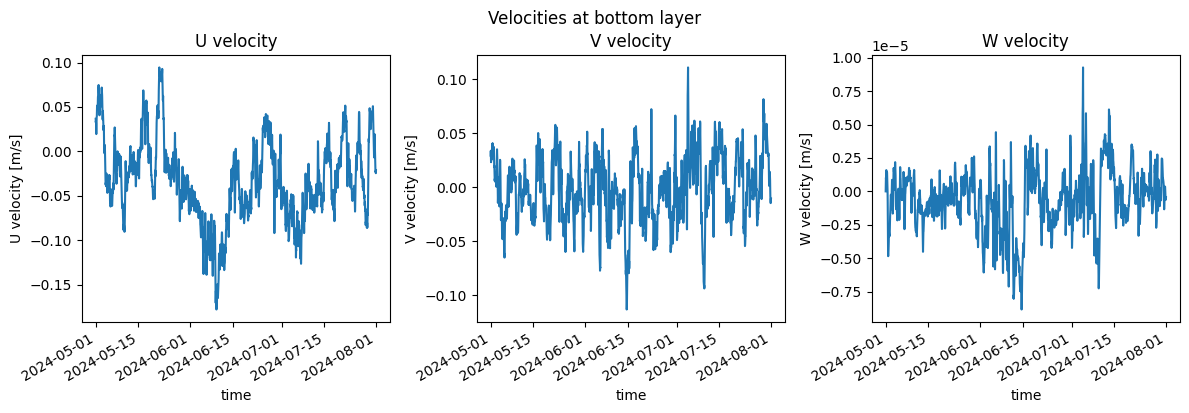

In [14]:
# Select spatial point and plot items
p = (12.5, 55.5)
fig,axs = plt.subplots(1,3, figsize=(12,4))
ds3["U velocity"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[0],title="U velocity")
ds3["V velocity"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[1],title="V velocity")
ds3["W velocity"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[2],title="W velocity")
plt.tight_layout()
plt.suptitle("Velocities at top layer", y=1.02)
plt.show()

# Select spatial point and plot items
p = (12.5, 55.5)
fig,axs = plt.subplots(1,3, figsize=(12,4))
ds3["U velocity"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[0],title="U velocity")
ds3["V velocity"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[1],title="V velocity")
ds3["W velocity"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[2],title="W velocity")
plt.tight_layout()
plt.suptitle("Velocities at bottom layer", y=1.02)
plt.show()

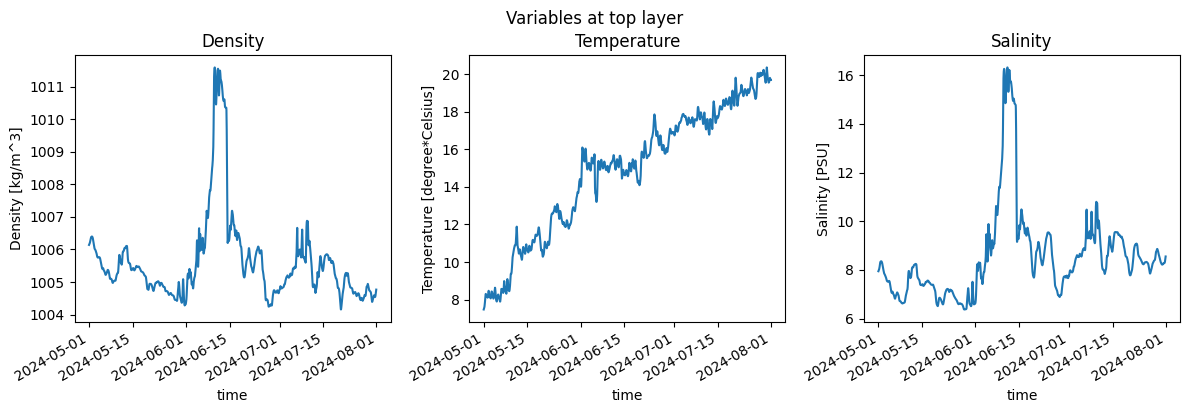

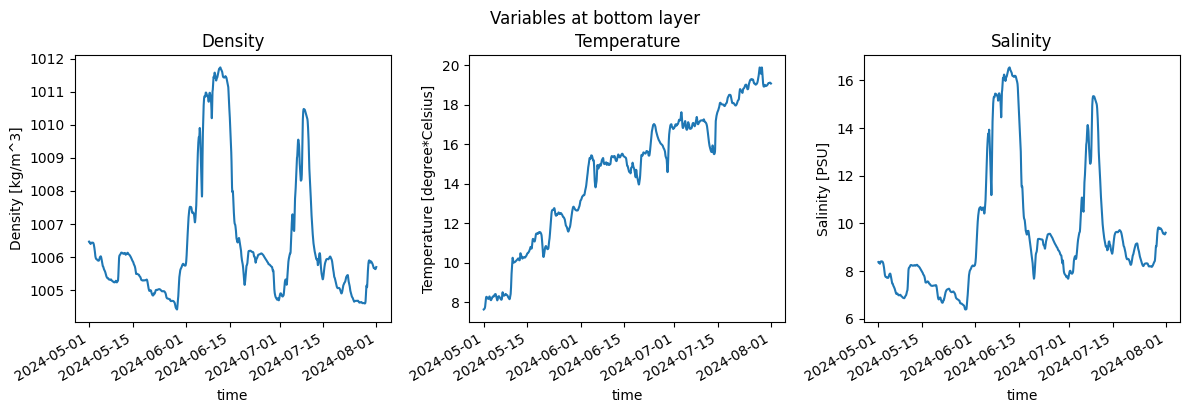

In [15]:
# Select spatial point and plot items
p = (12.5, 55.5)
fig,axs = plt.subplots(1,3, figsize=(12,4))
ds3["Density"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[0],title="Density")
ds3["Temperature"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[1],title="Temperature")
ds3["Salinity"].sel(x=p[0],y=p[1],layers="top").plot(ax=axs[2],title="Salinity")
plt.tight_layout()
plt.suptitle("Variables at top layer", y=1.02)
plt.show()

# Select spatial point and plot items
p = (12.5, 55.5)
fig,axs = plt.subplots(1,3, figsize=(12,4))
ds3["Density"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[0],title="Density")
ds3["Temperature"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[1],title="Temperature")
ds3["Salinity"].sel(x=p[0],y=p[1],layers="bottom").plot(ax=axs[2],title="Salinity")
plt.tight_layout()
plt.suptitle("Variables at bottom layer", y=1.02)
plt.show()